#### Taplend Loan Prediction
**Goal:** Use the application data and the loan performance data to decide which new applicants should get a loan.

## 1. Import libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score, accuracy_score

sns.set_style("whitegrid")

## 2. Load the data

In [ ]:
file_path = "Assessment_-_Data_Scientist.xlsx"

app_df = pd.read_excel(file_path, sheet_name="Application Data")
loan_df = pd.read_excel(file_path, sheet_name="Loan Performance")

print("Application data shape:", app_df.shape)
print("Loan performance shape:", loan_df.shape)

Application data shape: (647, 31)
Loan performance shape: (1285, 2)


In [ ]:
app_df.head()

,customer_id,amount_requested,birth_date,status,residence_rent_or_own,monthly_rent_amount,bank_account_direct_deposit,application_when,loan_duration,payment_ach,...,payment_frequency,home_phone_type,other_phone_type,how_use_money,monthly_income_amount,raw_l2c_score,raw_FICO_telecom,raw_FICO_retail,raw_FICO_bank_card,raw_FICO_money
0,9ece67d6c5,500,1991-08-21,Approved,True,0,True,2010-10-16 14:06:05,3,True,...,Semi-monthly,Mobile,NaN,Other,1560,614,574,600,656,561
1,5c2c402094,500,1990-07-24,Approved,True,0,False,2010-10-17 13:01:53,6,True,...,Bi-weekly,Mobile,NaN,Other,900,708,501,550,651,563
2,e6254cad30,400,1980-09-13,Approved,True,620,True,2010-10-17 19:52:34,6,True,...,Bi-weekly,Mobile,NaN,Other,1434,687,522,561,661,598
3,49fb42f51d,500,1976-09-10,Approved,False,785,False,2010-10-18 07:05:00,4,True,...,Bi-weekly,Mobile,NaN,Other,1600,616,560,552,634,591
4,195fbe5739,300,1979-12-01,Approved,True,700,True,2010-10-19 10:58:40,4,True,...,Bi-weekly,Mobile,Home,Other,1360,681,603,654,659,636


In [ ]:
loan_df.head()

,idLoan,flgGood
0,0DBA6B011D-01,Bad
1,96ACBBA7ED-01,Bad
2,289421D82A-01,Bad
3,9ECE67D6C5-01,Good
4,5C2C402094-01,Bad


In [ ]:
app_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 647 entries, 0 to 646
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   customer_id                  647 non-null    object        
 1   amount_requested             647 non-null    int64         
 2   birth_date                   647 non-null    datetime64[ns]
 3   status                       647 non-null    object        
 4   residence_rent_or_own        647 non-null    bool          
 5   monthly_rent_amount          647 non-null    int64         
 6   bank_account_direct_deposit  647 non-null    bool          
 7   application_when             647 non-null    datetime64[ns]
 8   loan_duration                647 non-null    int64         
 9   payment_ach                  647 non-null    bool          
 10  num_payments                 647 non-null    int64         
 11  payment_amount               647 non-null    

## 3. Merge the two datasets

- `idLoan` looks like `0DBA6B011D-01`. The part before `-` is the `customer_id`, and `-01` means first loan.
- Some customers have a second loan (`-02`). The application data has only one row per customer, so I keep **only the first loan**.
- **Excel problem:** a few `customer_id` values in the application sheet were turned into numbers by Excel (for example `0902431691` became `902431691`, and `00413198E8` became a very big number). A normal merge would lose these customers. To fix this, I convert both sides to the same format before merging.

In [ ]:
# Get customer id and loan number

loan_df["customer_id"] = loan_df["idLoan"].str[:-3].str.lower()
loan_df["loan_number"] = loan_df["idLoan"].str[-2:].astype(int)

print("Loans before:", len(loan_df)) # Returns the number of rows in load_df
loan_df = loan_df.sort_values("loan_number").drop_duplicates("customer_id")
# By default, By default, drop_duplicates() keeps the first occurrence of each customer ID and removes later occurrences.
print("Loans after keeping first loan only:", len(loan_df))

Loans before: 1285
Loans after keeping first loan only: 1269


In [ ]:
# Cleaning customer_ids before merging
# Mark bad loans as 1 and good loans as 0

def clean_id(x):
    text = str(x).strip().lower()
    try:
        number = float(text)
        if np.isfinite(number):     # very long ids can become "inf", so skip those
            return str(number)
    except ValueError:
        pass
    return text

app_df["customer_key"] = app_df["customer_id"].apply(clean_id)
loan_df["customer_key"] = loan_df["customer_id"].apply(clean_id)

loan_df["is_bad"] = (loan_df["flgGood"] == "Bad").astype(int)

df = app_df.merge(loan_df[["customer_key", "is_bad"]], on="customer_key", how="inner")

print("Applications:", len(app_df))
print("Merged rows:", len(df))
print("Applications without an outcome:", len(app_df) - len(df))
print("Loan outcomes without an application:", len(loan_df) - len(df))

Applications: 647
Merged rows: 643
Applications without an outcome: 4
Loan outcomes without an application: 626


**What I see:** Only about half of the loan outcomes have an application record, so about half of the labels cannot be used. This is an important limitation of the data.

In [ ]:
# Compare bad-loan rates for matched and unmatched records

matched = loan_df["customer_key"].isin(app_df["customer_key"])
print("Bad rate - matched loans  :", round(loan_df.loc[matched, "is_bad"].mean(), 3))
print("Bad rate - unmatched loans:", round(loan_df.loc[~matched, "is_bad"].mean(), 3))

# matched selects loans whose customers exist in the application sheet.
# ~matched reverses the Boolean values, selecting loans whose customers do not exist in the application sheet.

Bad rate - matched loans  : 0.551
Bad rate - unmatched loans: 0.254


The bad rate is very different in the two groups (about 55% vs 25%). So the loans I can use for modelling may not represent all loans.

Interpretation: Approximately 55 out of every 100 loans were bad.

## 4. Check the data quality

In [ ]:
df.isnull().sum()[df.isnull().sum() > 0]

,0
payment_amount_approved,20
bank_account_duration,1
other_phone_type,281
how_use_money,2


### Summary of Missing Values Handling:
- **`payment_amount_approved`**: Excluded from the model features entirely because it is decided post-approval (prevents data leakage).
- **`bank_account_duration`**: Handled automatically in the modeling pipeline using `SimpleImputer` with the `most_frequent` strategy.
- **`other_phone_type`**: Converted into a binary indicator feature `has_other_phone` (1 if present, 0 if missing/NaN).
- **`how_use_money`**: Categorized into `purpose_group`, mapping missing values safely to an `'Unknown'` category.

In [ ]:
print("Duplicate customers:", df["customer_key"].duplicated().sum())
print("Status values:", df["status"].unique())

print("\n")
print("payment_ach values:")
print(df["payment_ach"].value_counts())

print("\n")
print("Application dates Range:", df["application_when"].min(), "to", df["application_when"].max())

print("\n")
print("Bad loan counts:")
print(df["is_bad"].value_counts())

Duplicate customers: 0
Status values: ['Approved']


payment_ach values:
payment_ach
True     642
False      1
Name: count, dtype: int64


Application dates Range: 2010-10-16 14:06:05 to 2011-04-17 21:15:49


Bad loan counts:
is_bad
1    354
0    289
Name: count, dtype: int64


In [ ]:
print(df['raw_l2c_score'].describe())
print("\n")

print(df["raw_l2c_score"].value_counts().sort_index())

count    643.000000
mean     594.474339
std      122.853738
min       50.000000
25%      539.500000
50%      589.000000
75%      669.000000
max      808.000000
Name: raw_l2c_score, dtype: float64


raw_l2c_score
50     7
87     1
183    1
221    1
231    2
      ..
768    3
771    4
780    2
785    2
808    3
Name: count, Length: 171, dtype: int64


In [ ]:
fico_cols = [
    "raw_FICO_telecom",
    "raw_FICO_retail",
    "raw_FICO_bank_card",
    "raw_FICO_money"
]

print(df[fico_cols].describe())
print("\n")

for col in fico_cols:
    print(
        col,
        "Count of 222:",
        (df[col] == 222).sum()
    )


mask = (df[fico_cols] == 222).any(axis=1)

print("\n")
print(df.loc[mask, ["customer_id"] + fico_cols])

       raw_FICO_telecom  raw_FICO_retail  raw_FICO_bank_card  raw_FICO_money
count        643.000000       643.000000          643.000000      643.000000
mean         568.754277       596.648523          665.046656      603.027994
std           42.807749        52.119748           39.939296       27.774108
min          222.000000       222.000000          222.000000      222.000000
25%          537.000000       556.000000          645.500000      588.000000
50%          568.000000       594.000000          671.000000      605.000000
75%          597.000000       637.500000          680.000000      620.000000
max          712.000000       756.000000          797.000000      662.000000


raw_FICO_telecom Count of 222: 1
raw_FICO_retail Count of 222: 1
raw_FICO_bank_card Count of 222: 1
raw_FICO_money Count of 222: 1


   customer_id  raw_FICO_telecom  raw_FICO_retail  raw_FICO_bank_card  \
69  831b70959f               222              222                 222   

    raw_FICO_money  
69  

##### A `raw FICO score` of 222 appears to be a potential missing-value code because it is significantly lower than the normal score distribution, occurs only once in each of the four FICO columns, and all four occurrences belong to the same customer.

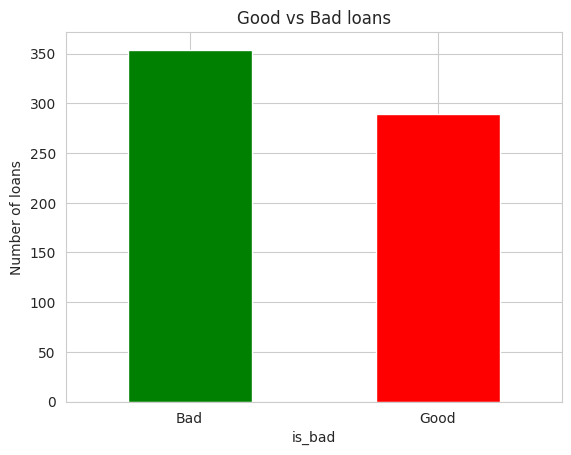

In [ ]:
df["is_bad"].value_counts().rename({0: "Good", 1: "Bad"}).plot(kind="bar", rot=0, color=["green", "red"])
plt.title("Good vs Bad loans")
plt.ylabel("Number of loans")
plt.show()

**# Data issues found so far**
- Every applicant in the data was approved, so we know nothing about people who were declined.
- `payment_ach` is almost always True, so it is not useful.
- A raw FICO score of 222 looks like a "missing score" code, not a real score.

## 5. Clean the data and create features

In [ ]:
# Create age and income ratios
# Treat 222 as a missing FICO score
# Group loan purpose labels
# Check whether another phone is listed

df["age"] = (df["application_when"] - df["birth_date"]).dt.days / 365.25

income = df["monthly_income_amount"].replace(0, np.nan)
df["rent_to_income"] = (df["monthly_rent_amount"] / income).clip(upper=3)
df["loan_to_income"] = (df["amount_requested"] / income).clip(upper=3)

fico_cols = ["raw_FICO_telecom", "raw_FICO_retail", "raw_FICO_bank_card", "raw_FICO_money"]
df[fico_cols] = df[fico_cols].replace(222, np.nan)
df["fico_mean"] = df[fico_cols].mean(axis=1)

def group_purpose(x):
    if pd.isna(x):
        return "Unknown"
    if x.startswith("Bills"):
        return "Bills"
    if x in ["Medical", "Car", "Other"]:
        return x
    return "Other"

df["purpose_group"] = df["how_use_money"].apply(group_purpose)

df["has_other_phone"] = df["other_phone_type"].notna().astype(int) # creates a binary feature

df[["age", "rent_to_income", "loan_to_income", "fico_mean"]].describe().round(2)

,age,rent_to_income,loan_to_income,fico_mean
count,643.00,643.00,643.00,642.00
mean,42.62,0.24,0.30,608.97
std,12.36,0.18,0.18,33.25
min,18.08,0.00,0.04,501.00
25%,32.75,0.13,0.18,585.31
50%,41.72,0.24,0.26,607.75
75%,51.37,0.35,0.37,630.25
max,79.78,1.14,1.67,725.25


In [ ]:
df["purpose_group"].value_counts()

,count
purpose_group,
Other,356
Bills,246
Car,29
Medical,10
Unknown,2


## 6. Exploratory Data Analysis

### 6.1 Bad-loan rate by category (red line = overall bad rate)

Overall bad rate: 0.551


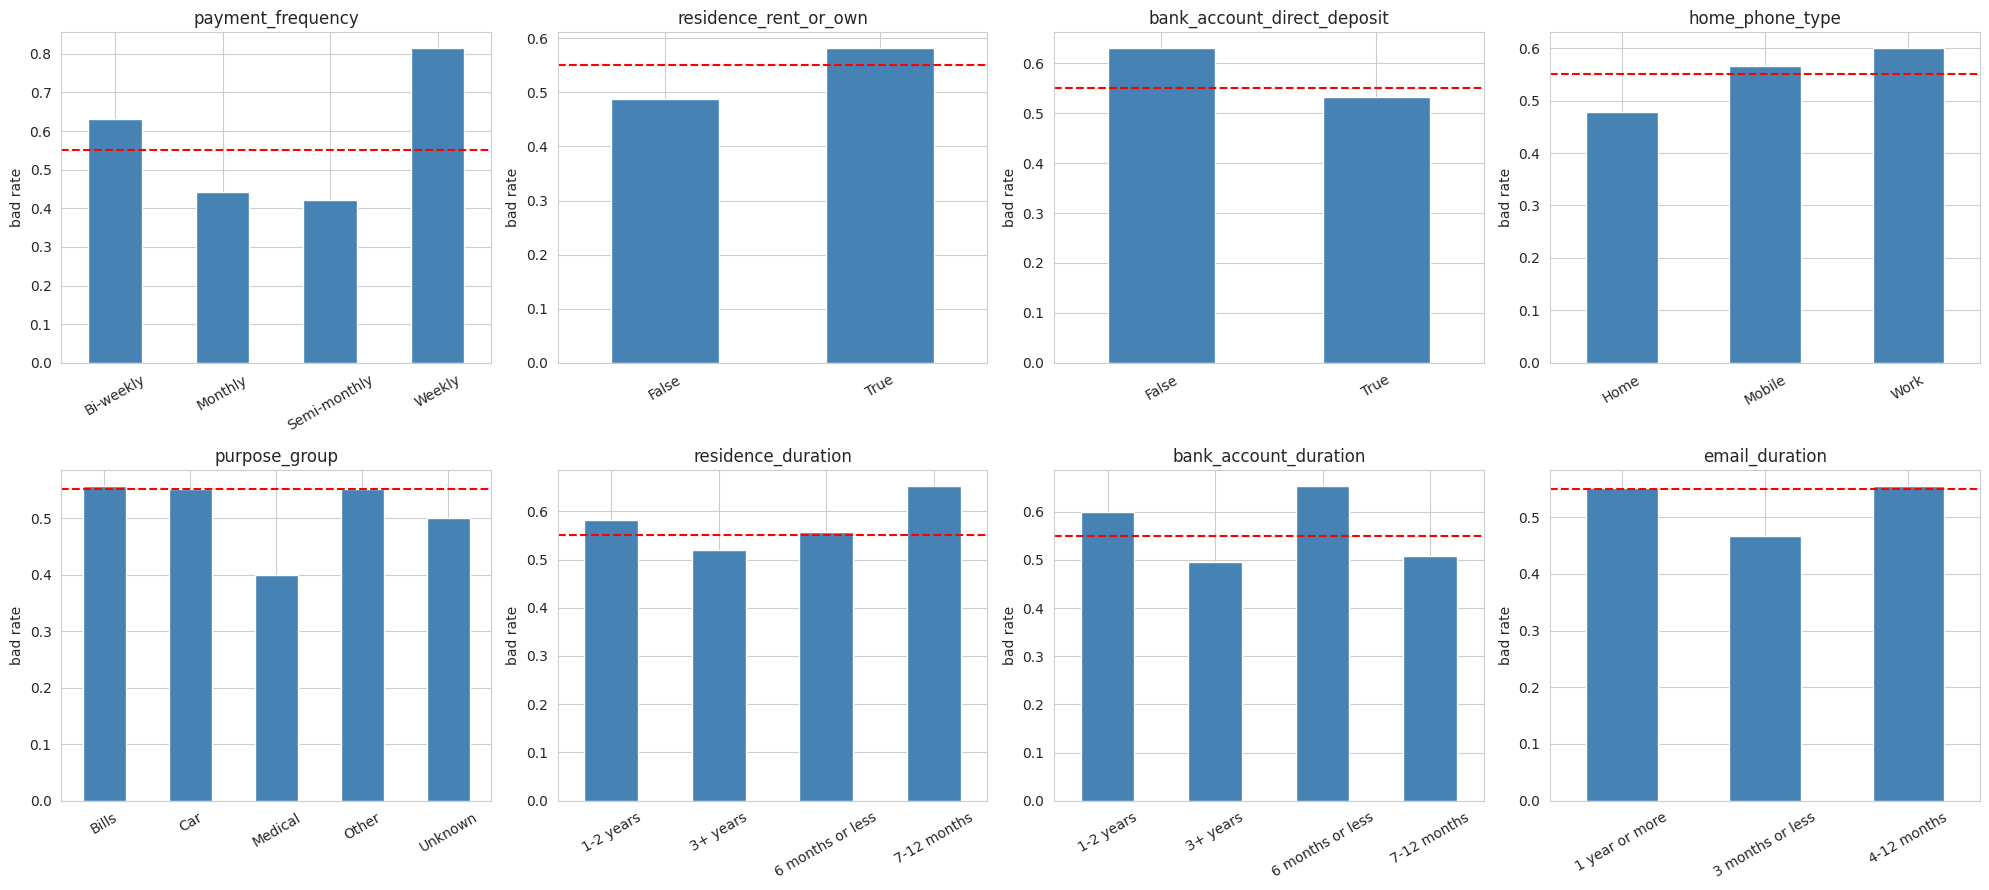

In [ ]:
overall_bad = df["is_bad"].mean()
print("Overall bad rate:", round(overall_bad, 3))

cat_cols = ["payment_frequency", "residence_rent_or_own", "bank_account_direct_deposit",
            "home_phone_type", "purpose_group", "residence_duration",
            "bank_account_duration", "email_duration"]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, cat_cols):
    df.groupby(col)["is_bad"].mean().plot(kind="bar", ax=ax, rot=30, color="steelblue")
    ax.axhline(overall_bad, color="red", linestyle="--")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("bad rate")
plt.tight_layout()
plt.show()

In [ ]:
# Show rates for a few key categories

for col in ["payment_frequency", "bank_account_direct_deposit"]:
    print(df.groupby(col)["is_bad"].agg(["mean", "count"]).round(3))
    print()

                    mean  count
payment_frequency              
Bi-weekly          0.631    328
Monthly            0.442    172
Semi-monthly       0.422    116
Weekly             0.815     27

                              mean  count
bank_account_direct_deposit              
False                        0.630    119
True                         0.532    524



**Observations**
- **Payment frequency** shows the biggest difference: weekly payers have a very high bad rate, monthly and semi-monthly payers have a much lower one.
- Applicants **without direct deposit** have a higher bad rate.
- Other features show smaller differences.

### 6.2 Numeric features

fico_mean               -0.219
raw_FICO_retail         -0.204
raw_FICO_money          -0.203
raw_FICO_bank_card      -0.192
raw_FICO_telecom        -0.180
age                     -0.154
monthly_rent_amount     -0.024
rent_to_income          -0.019
monthly_income_amount   -0.011
loan_to_income           0.015
raw_l2c_score            0.022
amount_requested         0.043
Name: is_bad, dtype: float64


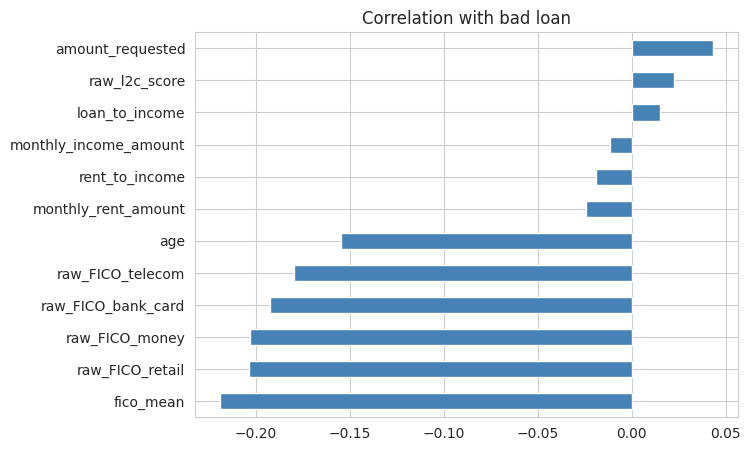

In [ ]:
num_cols = ["age", "monthly_income_amount", "monthly_rent_amount", "rent_to_income",
            "amount_requested", "loan_to_income", "raw_l2c_score"] + fico_cols + ["fico_mean"]

corr = df[num_cols + ["is_bad"]].corr()["is_bad"].drop("is_bad").sort_values()
print(corr.round(3))

corr.plot(kind="barh", figsize=(7, 5), color="steelblue")
plt.title("Correlation with bad loan")
plt.show()

Higher credit scores and higher age go with fewer bad loans (negative correlation). Income and rent show almost no relationship. `raw_l2c_score` has almost zero correlation, which is strange for a score and should be questioned.

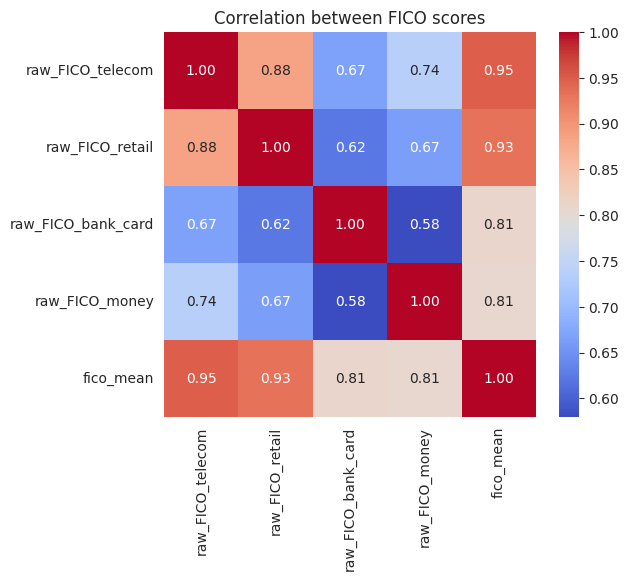

In [ ]:
# Checking the similarity between the FICO scores

plt.figure(figsize=(6, 5))
sns.heatmap(df[fico_cols + ["fico_mean"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between FICO scores")
plt.show()

The four FICO scores are strongly correlated with each other, so using all of them adds little. I use the **average (`fico_mean`)** in the model.

          mean  count
month                
2010-10  0.688     16
2010-11  0.661     56
2010-12  0.554     83
2011-01  0.618    110
2011-02  0.574    129
2011-03  0.461    152
2011-04  0.495     97


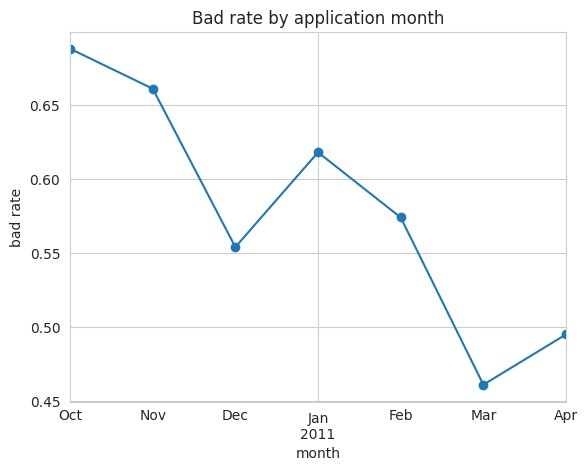

In [ ]:
# Check bad-loan rate by month

df["month"] = df["application_when"].dt.to_period("M")
monthly = df.groupby("month")["is_bad"].agg(["mean", "count"]).round(3)
print(monthly)
monthly["mean"].plot(marker="o", title="Bad rate by application month")
plt.ylabel("bad rate")
plt.show()

In [ ]:
column_info = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.values,
})

print(column_info)

                    Column Name       Data Type
0                   customer_id          object
1              amount_requested           int64
2                    birth_date  datetime64[ns]
3                        status          object
4         residence_rent_or_own            bool
5           monthly_rent_amount           int64
6   bank_account_direct_deposit            bool
7              application_when  datetime64[ns]
8                 loan_duration           int64
9                   payment_ach            bool
10                 num_payments           int64
11               payment_amount         float64
12              amount_approved           int64
13            duration_approved           int64
14      payment_amount_approved         float64
15                  address_zip           int64
16                        email          object
17          bank_routing_number           int64
18               email_duration          object
19           residence_duration         

## 7. Prepare data for modelling

**Columns I do NOT use**
- `customer_id`, `email`, `bank_routing_number`, `address_zip`: identifiers, not real predictors.
- `payment_amount`, `num_payments`, `amount_approved`, `duration_approved`, `payment_amount_approved`: these are decided **after** approval, so they should not be used to decide approval.
- `payment_ach`: almost constant.
- `birth_date`, `application_when`: replaced by `age`.

In [ ]:
# 1. Numerical features
numeric_features = [
    "age","monthly_income_amount","monthly_rent_amount","rent_to_income",
    "amount_requested","loan_duration","loan_to_income",
    "fico_mean","raw_l2c_score"
]

# 2. Binary features
binary_features = [
    "residence_rent_or_own","bank_account_direct_deposit","has_other_phone"
]

# 3. Categorical features
categorical_features = [
    "payment_frequency","residence_duration","bank_account_duration",
    "email_duration","home_phone_type","purpose_group"
]

feature_cols = (
    numeric_features + binary_features + categorical_features
)

X = df[feature_cols].copy()
y = df["is_bad"].copy()

X[binary_features] = X[binary_features].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (643, 18)
y shape: (643,)


In [ ]:
# Dividing data into 80-20 ratio

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Train rows: 514 | Test rows: 129


## 8. Build the models

In [ ]:
# Fill missing values and encode the categories

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, C=0.1),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=2,
                                                    learning_rate=0.05, random_state=42),
}

pipelines = {name: Pipeline([("prep", preprocessor), ("model", m)]) for name, m in models.items()}

### 8.1 Cross-validation on the training data
The dataset is small, so one test split can be lucky or unlucky. I first compare the models with 5-fold cross-validation, which is more stable.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    cv_results.append({"Model": name, "CV AUC (mean)": scores.mean(), "CV AUC (std)": scores.std()})

cv_df = pd.DataFrame(cv_results).round(3)
cv_df

,Model,CV AUC (mean),CV AUC (std)
0,Logistic Regression,0.646,0.052
1,Random Forest,0.641,0.053
2,Gradient Boosting,0.639,0.055


### 8.2 Test-set results

In [ ]:
def ks_stat(y_true, prob):
    fpr, tpr, _ = roc_curve(y_true, prob)
    return (tpr - fpr).max()

rows = []
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    rows.append({
        "Model": name,
        "Test AUC": roc_auc_score(y_test, prob),
        "KS": ks_stat(y_test, prob),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
    })

test_df = pd.DataFrame(rows).round(3)
test_df

,Model,Test AUC,KS,Accuracy,Precision,Recall
0,Logistic Regression,0.610,0.200,0.566,0.603,0.620
1,Random Forest,0.604,0.250,0.566,0.590,0.690
2,Gradient Boosting,0.603,0.227,0.558,0.585,0.676


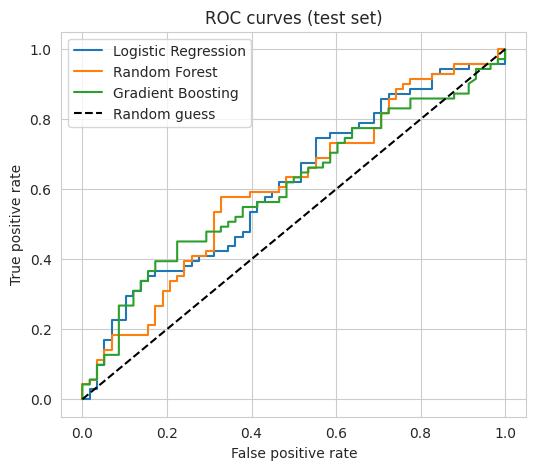

In [ ]:
# Compare ROC curves

plt.figure(figsize=(6, 5))
for name, pipe in pipelines.items():
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves (test set)")
plt.legend()
plt.show()

**Result:** All models have only a small advantage over random guessing (AUC 0.5). The credit-score and application information carries some signal but it is weak. The models perform about the same, so I choose the simplest one, **Logistic Regression**, because it is easy to explain and less likely to overfit on 600+ rows.

### 8.3 What drives the prediction? (Logistic Regression coefficients)

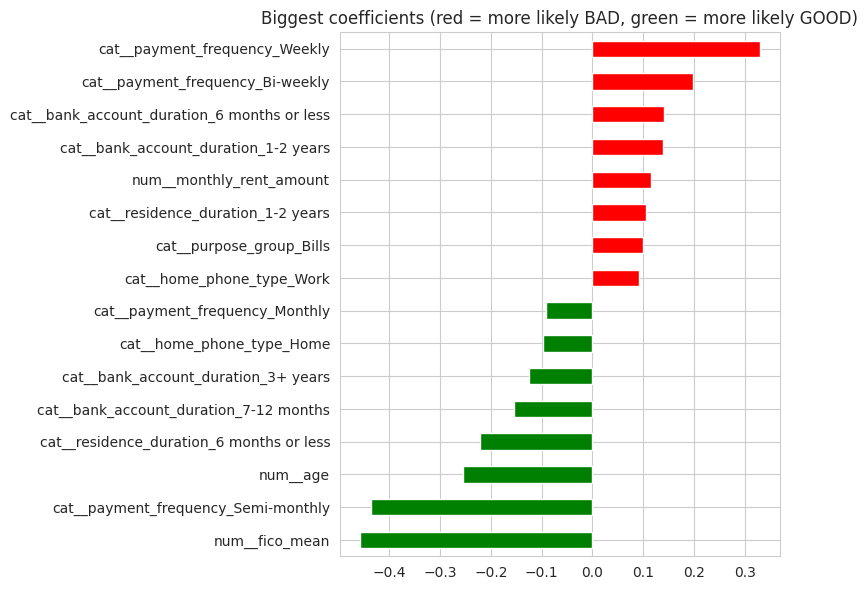

In [ ]:
final_model = pipelines["Logistic Regression"]

names = final_model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(final_model.named_steps["model"].coef_[0], index=names).sort_values()

top = pd.concat([coefs.head(8), coefs.tail(8)])
top.plot(kind="barh", figsize=(8, 6), color=["green" if v < 0 else "red" for v in top])
plt.title("Biggest coefficients (red = more likely BAD, green = more likely GOOD)")
plt.tight_layout()
plt.show()

## 9. Approval policy (choosing a cutoff)

The model gives each applicant a probability of being **bad**. The policy is: **approve if the probability of bad is below a cutoff**.

A lower cutoff is stricter (fewer approvals, lower bad rate). A higher cutoff approves more people but more of them go bad. To get a more reliable table, I use cross-validated predictions for **all** rows (each prediction comes from a model that did not see that row).

In [ ]:
cv_prob = cross_val_predict(pipelines["Logistic Regression"], X, y, cv=cv, method="predict_proba")[:, 1]

rows = []
for cutoff in [0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 1.01]:
    approved = cv_prob < cutoff
    rows.append({
        "Cutoff (approve if P(bad) <)": cutoff if cutoff < 1 else "No cutoff",
        "Applicants approved": int(approved.sum()),
        "% approved": round(approved.mean() * 100, 1),
        "Bad rate of approved (%)": round(y[approved].mean() * 100, 1) if approved.sum() > 0 else None,
        "Good loans lost": int(((~approved) & (y == 0)).sum()),
        "Bad loans avoided": int(((~approved) & (y == 1)).sum()),
    })

policy = pd.DataFrame(rows)
policy

,Cutoff (approve if P(bad) <),Applicants approved,% approved,Bad rate of approved (%),Good loans lost,Bad loans avoided
0,0.35,65,10.1,27.7,242,336
1,0.4,111,17.3,36.9,219,313
2,0.45,176,27.4,39.2,182,285
3,0.5,241,37.5,40.2,145,257
4,0.55,307,47.7,45.3,121,215
5,0.6,385,59.9,48.8,92,166
6,0.65,466,72.5,49.6,54,123
7,0.7,533,82.9,51.2,29,81
8,No cutoff,643,100.0,55.1,0,0


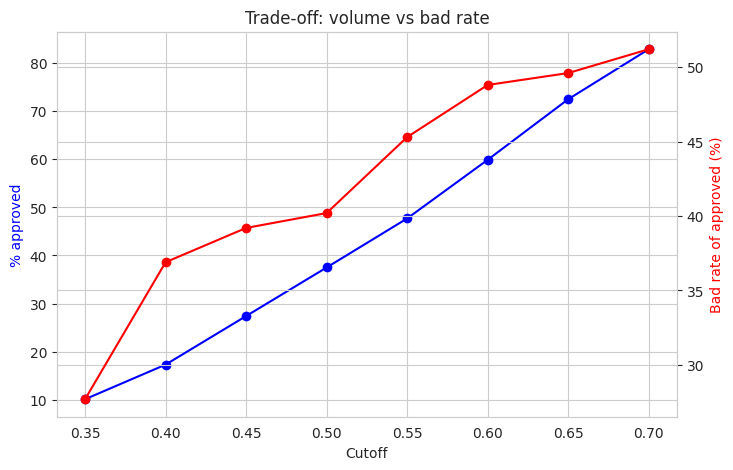

In [ ]:
plot_df = policy.iloc[:-1]
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(plot_df.iloc[:, 0], plot_df["% approved"], marker="o", color="blue", label="% approved")
ax1.set_xlabel("Cutoff")
ax1.set_ylabel("% approved", color="blue")
ax2 = ax1.twinx()
ax2.plot(plot_df.iloc[:, 0], plot_df["Bad rate of approved (%)"], marker="o", color="red", label="Bad rate")
ax2.set_ylabel("Bad rate of approved (%)", color="red")
plt.title("Trade-off: volume vs bad rate")
plt.show()

**Recommended policy**

The bad rate in this data is about 55% before any filtering, which is very high. A cutoff of **0.50** approves about 40% of the applicants and brings the bad rate down from about 55% to about 42%. A cutoff of **0.40** is safer (bad rate about 37%) but approves only about 17% of applicants. A cutoff of **0.55** approves about half the applicants with a bad rate of about 46%. The business should pick the cutoff using its profit per good loan and loss per bad loan.

I would also add two simple rules from the EDA: be careful with **weekly payment frequency** and with applicants who have **low credit scores**.

The model is only a ranking tool. It should not be the only thing used to approve or decline someone (see limitations).

## 10. Save the model

In [ ]:
# Train the final model and save it

import joblib
final_model.fit(X, y)          # train final model on all data
joblib.dump(final_model, "taplend_loan_model.joblib")
print("Model saved")

Model saved


## 11. Problems and limitations of the data
1. **Only half of the outcomes can be used.** About 626 loans in `Loan Performance` have no matching application. The bad rate of these (about 25%) is very different from the matched loans (about 55%), so the sample may not represent all loans.
2. **Selection bias.** All applicants in the data were already approved. We have no information on declined applicants, so the model only learns from people who passed the old rules.
3. **Small dataset.** About 640 rows. Results change with a different split, so the numbers are not very stable.
4. **Short time period.** Only Oct 2010 to Apr 2011 (6 months). We cannot check seasonality or economic cycles.
5. **Messy fields.** Excel changed some customer ids, `how_use_money` has overlapping labels, FICO has a "222" missing code, and `other_phone_type` is missing for 44%.
6. **Repeat loans.** Some customers have a second loan. I kept only the first one.
7. **Strange score.** `raw_l2c_score` has almost no link to the outcome even though it looks like the lender's own score.
8. **No money amounts for outcomes.** Good/Bad is only a label. We do not know how much was lost or earned.

## 12. Shortcomings of my analysis
- The model is weak (test AUC about 0.59 and cross-validated AUC about 0.65, where 0.5 is random guessing), so it should not be used for fully automatic decisions.
- The test set is small (about 129 rows), so the test AUC has a large margin of error.
- Because of the selection bias, the model cannot tell how risky **declined** types of people are.
- I dropped the loan-term fields (payment amount, number of payments) because they are set after approval. This is a judgment call.
- I did not tune the models much, to avoid overfitting a small dataset.
- The cutoff is based on bad rate only. I did not use profit, interest or fees because they are not in the data.

## 13. Additional data that would help
- **Declined applicants** and their details (to fix the selection bias)
- **Loan balance, amount repaid and amount lost** (to measure profit, not only Good/Bad)
- **Days past due and time to default**
- **Repeat-borrower history** with the same lender
- **Real credit bureau history** (past defaults, number of loans, utilization)
- **Verified income and employment** (income is self-reported)
- **Interest rate and fees** for each loan
- **Longer time period** (at least 2-3 years)